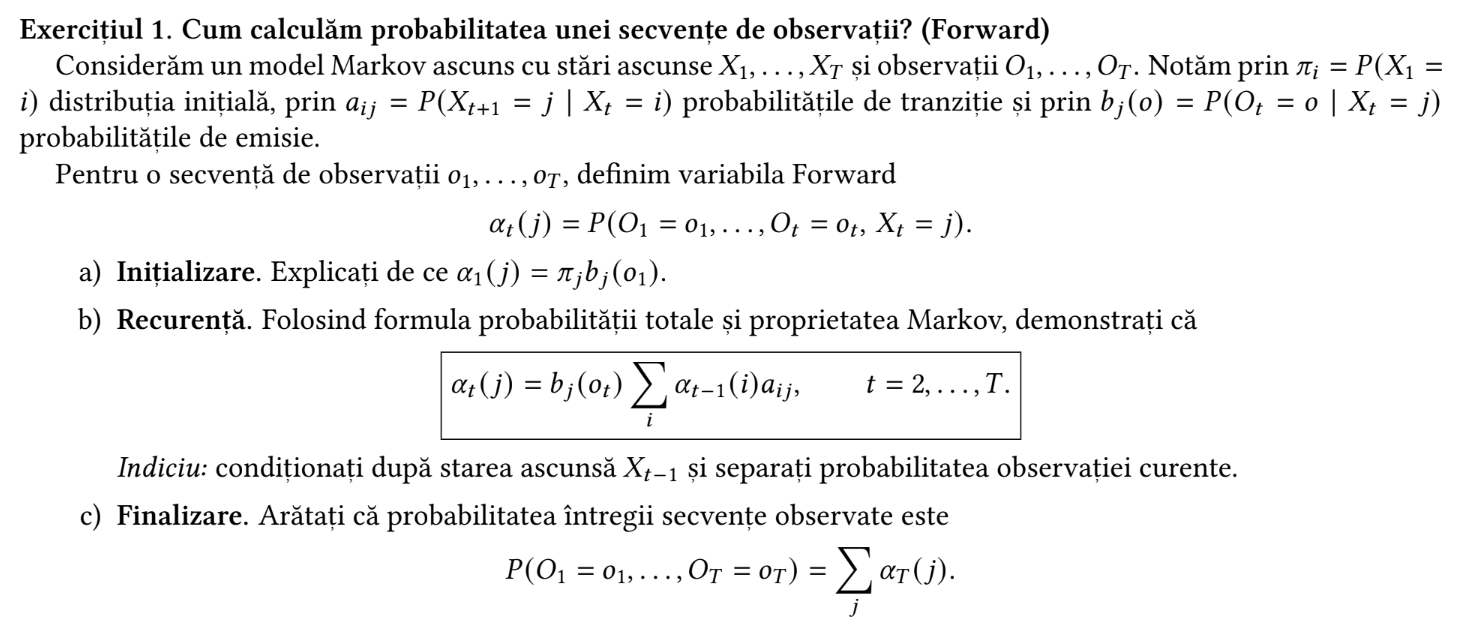

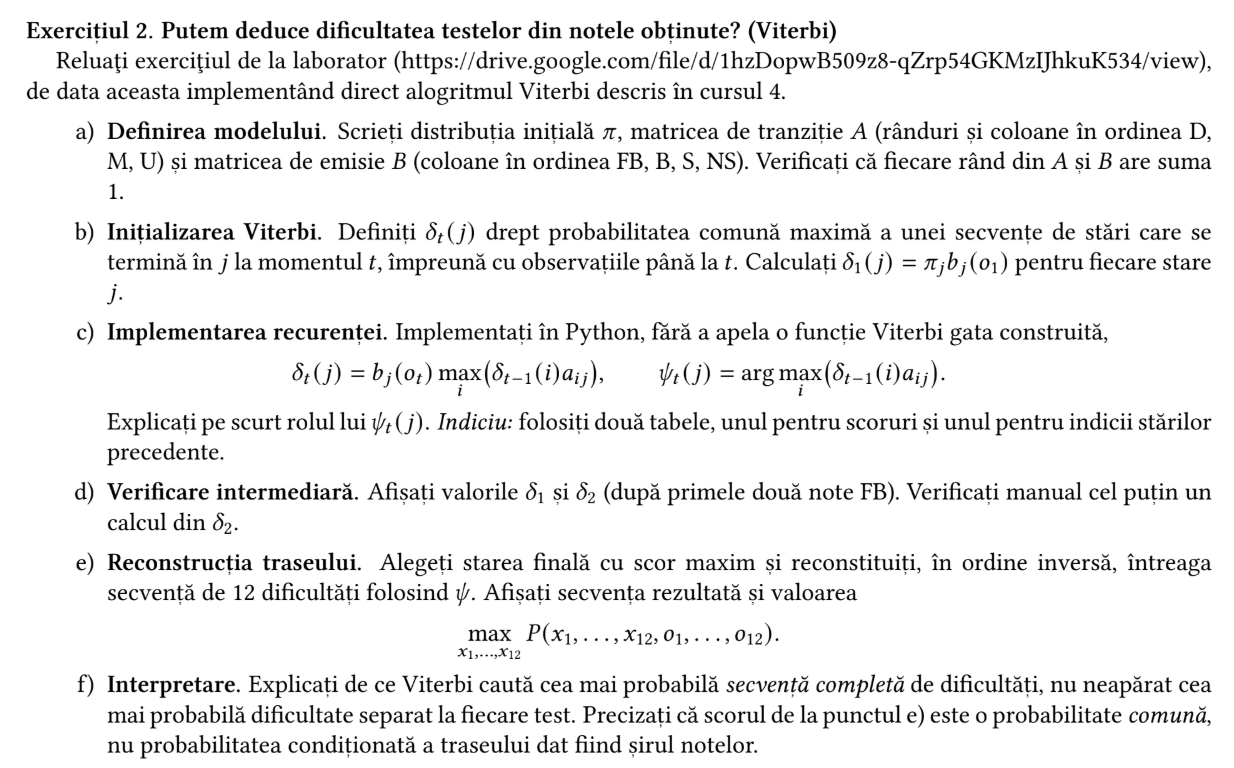

In [2]:
import numpy as np

stari = ['D', 'M', 'U']
note = ['FB', 'B', 'S', 'NS']
obs = [0, 0, 2, 1, 1, 2, 1, 1, 3, 1, 1, 2]

probinit = np.array([1/3, 1/3, 1/3])

A = np.array([
    [0.0,  0.5,  0.5 ], # de la D
    [0.5,  0.25, 0.25], # de la M
    [0.5,  0.25, 0.25]  # de la U
])

B = np.array([
    [0.1,  0.2,  0.4, 0.3], # D
    [0.15, 0.25, 0.5, 0.1], # M
    [0.2,  0.3,  0.4, 0.1]  # U
])


In [9]:
#b
T = len(obs)
N = len(stari)

delta = np.zeros((T, N))

for j in range(len(stari)):
    delta[0][j] = probinit[j] * B[j][0]

In [13]:
psi = np.zeros((T, N), dtype=int)

for t in range(1, T):
    for j in range(N):
        prob_tranzitii = delta[t-1] * A[:, j]

        delta[t, j] = B[j, obs[t]] * np.max(prob_tranzitii)
        psi[t, j] = np.argmax(prob_tranzitii)

#d
print("delta_1 ", delta[0])
print("delta_2 ", delta[1])

#e
traseu = np.zeros(T, dtype=int)
traseu[T-1] = np.argmax(delta[T-1])
scor_maxim = np.max(delta[T-1])

for t in range(T-2, -1, -1):
    traseu[t] = psi[t+1, traseu[t+1]]

secventa_stari = [stari[idx] for idx in traseu]
print(f"{secventa_stari=}")
print(f"{scor_maxim=}")

delta_1  [0.03333333 0.05       0.06666667]
delta_2  [0.00333333 0.0025     0.00333333]
secventa_stari=['D', 'U', 'D', 'U', 'D', 'M', 'D', 'U', 'D', 'U', 'D', 'M']
scor_maxim=np.float64(2.1093750000000005e-11)


daca am calcula cea mai probabila dificultate separat pentru fiecare test, am obtine un optim local, fara sa luam in calcul prob de a ajunge pana la starea anterioara. adica am verifica doar prob de tranzitie in loc sa verificam prob tranzitie * prob de a fi in starea anterioara la momentul t-1. viterbi calculeaza doar produse de prob. pentru a obtine prob starilor condititonata de obs, ar trebui sa impartim la P(O).